# Codebook 

**Plotting the prepared yearly and monthly data from Norkyst 2024 (Hindcast)**

- For information about the used datasets, refer to histogram_norkyst_yearly_seasonal.ipynb, where the yearly and monthly datasets were calculated. 

In [1]:
import numpy as np
import scipy as sp
import xarray as xr
import seaborn as sea
import matplotlib.pyplot as plt

In [2]:
from dataloader_inf import open_dataset

In [3]:
path = '/lustre/storeB/project/fou/hi/foccus/malene/run-ocean-anemoi/ppi/external_checkpoint_inference/results/rollout_benchmark_lr3.5e6-rs3-i0-m3/step_51000_e14/resampled_means'
year = open_dataset(f'{path}/yearly_mean.nc').ds
#year = year.rename_vars({'salinity_0' : 'salinity', 'temperature_0' : 'temperature', 'v_northward_0' : 'v_northward', 'u_eastward_0' : 'u_eastward'})
month = open_dataset(f'{path}/monthly_mean.nc').ds
#month = month.rename_vars({'salinity_0' : 'salinity', 'temperature_0' : 'temperature', 'v_northward_0' : 'v_northward', 'u_eastward_0' : 'u_eastward'})
#viewing files to ensure correct calculations: 
print(year.head())
print(month.head())

<xarray.Dataset> Size: 1kB
Dimensions:      (Y: 5, X: 5, time: 2)
Coordinates:
  * Y            (Y) float64 40B 0.0 800.0 1.6e+03 2.4e+03 3.2e+03
  * X            (X) float64 40B 0.0 800.0 1.6e+03 2.4e+03 3.2e+03
  * time         (time) datetime64[ns] 16B 2024-12-31 2025-12-31
Data variables:
    salinity     (time, Y, X) float32 200B ...
    temperature  (time, Y, X) float32 200B ...
    v_northward  (time, Y, X) float32 200B ...
    u_eastward   (time, Y, X) float32 200B ...
    zeta         (time, Y, X) float32 200B ...
<xarray.Dataset> Size: 3kB
Dimensions:      (Y: 5, X: 5, time: 5)
Coordinates:
  * Y            (Y) float64 40B 0.0 800.0 1.6e+03 2.4e+03 3.2e+03
  * X            (X) float64 40B 0.0 800.0 1.6e+03 2.4e+03 3.2e+03
  * time         (time) datetime64[ns] 40B 2024-01-01 2024-02-01 ... 2024-05-01
Data variables:
    salinity     (time, Y, X) float32 500B ...
    temperature  (time, Y, X) float32 500B ...
    u_eastward   (time, Y, X) float32 500B ...
    v_northward  (tim

In [13]:
#check if code from summer project is adaptable for this use case
sea.set_theme(style="darkgrid")
def histograms_with_specified_layout(ds, type_of_avg, type_to_check = 'time', time_to_check = 1, save_path = 'figures/histogram.png'):
    """
    Definition: 

    Arguments:
    arg[1] : dataset - the inference dataset 
    arg[2] : time to check (int) - the timestep in the data would you like the check the variable distribution for

    Outputs: 
    Figure of the variable distributions 
    """

    variables = ['salinity', 'u_eastward', 'v_northward', 'temperature', 'zeta']
    data = {var: ds[var].isel({type_to_check : time_to_check}).values.ravel() for var in variables}

    print(data)
    print(ds['salinity'])
    #now lets remove data outside of frame of reference
    if 'salinity' in variables: 
        data['salinity'] = ds['salinity'].where(ds['salinity'] > 30).values
    if 'zeta' in variables:
            data['zeta'] = ds['zeta'].where(ds['zeta'] > -0.7).values
    for var in ['u_eastward', 'v_northward']:
        if var in variables: 
            mask = (ds[var] >= -0.5) & (ds[var] <= 0.5)
            data[var] = ds[var].where(mask).values

    data = {var : values[~np.isnan(values)] for var, values in data.items()}

    fig = plt.figure(figsize = (12,7))
    titles = ['Salinity', 'U-Eastward', 'V-Northward', 'Temperature', 'Zeta']
    """ 
    Trying to make the plot more visually appealing witg gridspec, to elongate the bottom plots.
    """
    gs = fig.add_gridspec(2,6)
    axes = [fig.add_subplot(gs[0,0:2]), fig.add_subplot(gs[0,2:4]), fig.add_subplot(gs[0,4:6]), fig.add_subplot(gs[1,0:3]), fig.add_subplot(gs[1,3:6])]
    x_lims = {'salinity' : (30,35.5), 'u_eastward' : (-0.2,0.2), 'v_northward' : (-0.2,0.2), 'zeta' : (-0.6, 0)}
    y_lims = {'salinity' : (0, 1.5), 'zeta' : (0, 6.5), 'temperature' : (0,0.4), 'u_eastward' : (1e-1, 1e2), 'v_northward' : (1e-1, 1e2)}
    logs = {'u_eastward', 'v_northward'}
    for i, (var, values) in enumerate(data.items()):
        row, col = divmod(i,3)
        sea.histplot(values, bins = 30, kde = True, ax = axes[i], stat='density', color = 'royalblue', edgecolor = 'darkolivegreen')
        axes[i].set_title(titles[i], fontsize = 15)
        axes[i].set_facecolor("#C4C6D5")
        #axes[1,2].axis('off')
        units = {'salinity': '[g/kg]', 'u_eastward': '[m/s]', 'v_northward': '[m/s]', 'temperature': '[°C]', 'zeta': '[m]'}
        axes[i].set_xlabel(f'{units[var]}', fontsize=12)
        axes[i].set_ylabel('Probability Density', fontsize = 12)
        if var in x_lims:
            axes[i].set_xlim(x_lims[var])
        if var in y_lims: 
            axes[i].set_ylim(y_lims[var])
        if var in logs: 
            axes[i].set_yscale('log')
    plt.suptitle(f'Histogram & Density curve for Havbris variables - {type_of_avg} average', fontsize= 16)
    plt.tight_layout()
    fig.savefig(save_path)

{'salinity': array([      nan,       nan,       nan, ..., 34.29739 , 34.292473,
       34.292416], shape=(3153556,), dtype=float32), 'u_eastward': array([0.00016184, 0.00025359, 0.00019626, ..., 0.01558071, 0.01708309,
       0.0171069 ], shape=(3153556,), dtype=float32), 'v_northward': array([9.8777937e-06, 6.8541041e-05, 1.6755095e-05, ..., 1.3919354e-02,
       1.6742658e-02, 1.6734054e-02], shape=(3153556,), dtype=float32), 'temperature': array([      nan,       nan,       nan, ..., 2.5431879, 2.5459049,
       2.5391667], shape=(3153556,), dtype=float32), 'zeta': array([        nan,         nan,         nan, ..., -0.34069026,
       -0.34062687, -0.34065363], shape=(3153556,), dtype=float32)}
<xarray.DataArray 'salinity' (time: 2, Y: 1148, X: 2747)> Size: 25MB
array([[[      nan,       nan, ..., 33.828846, 34.3666  ],
        [      nan,       nan, ..., 34.29309 , 33.740192],
        ...,
        [      nan,       nan, ..., 34.299267, 34.292538],
        [      nan,       nan, ...

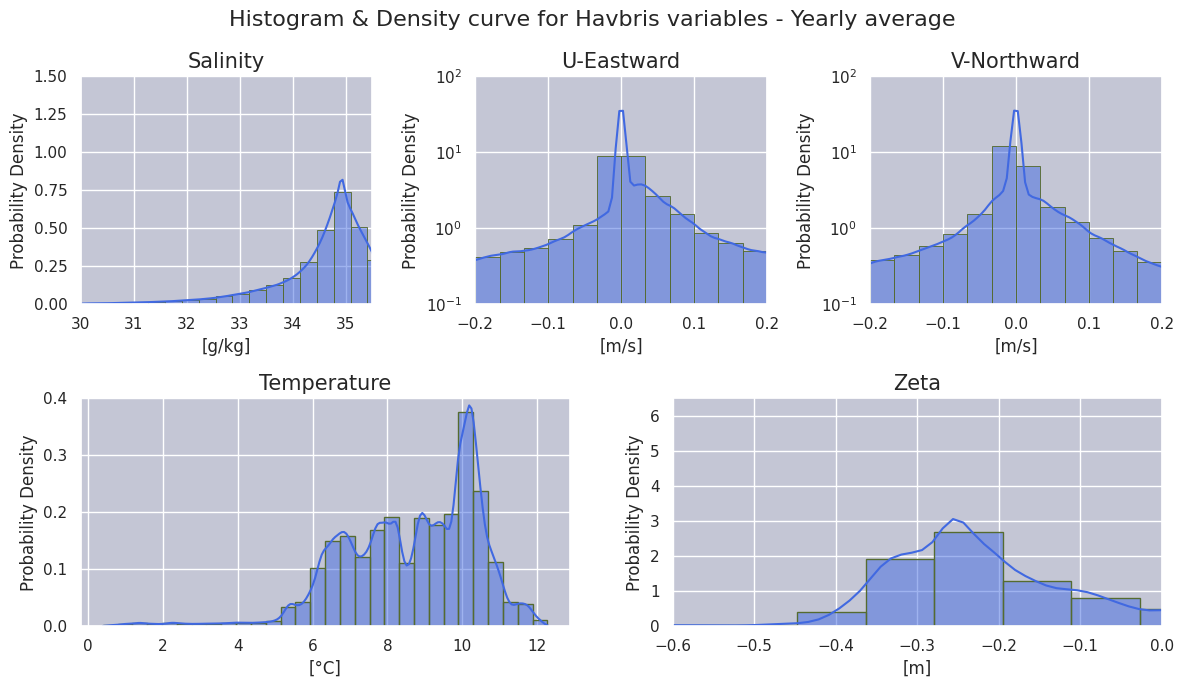

In [14]:
histograms_with_specified_layout(year, 'Yearly', time_to_check=0, save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/year.png')

In [18]:
def seasons(ds):
    #Then we make weights based on the number of days in the respective months
    month_length = ds.time.dt.days_in_month
    #Preview
    print(month_length)
    #Weights - tid per måned / summen av alle tider  
    weights = month_length.groupby('time.season') / month_length.groupby('time.season').sum(skipna = False)
    #testing to make sure the weights are correctly defined
    #weight_summed = np.testing.assert_allclose(weights.groupby('time.season').sum().values, np.ones(4)) 
    #if weight_summed != 1:
    #    raise ValueError(f'Weights are not properly defined - please ensure that the sum of weights for the seasons equal 1.0. Current sum is: {weight_summed}')
    #apply weights to dataset
    ds_weighted = (ds*weights).groupby('time.season').sum(dim = 'time', skipna = False)
    return ds_weighted 

In [19]:
seasons_ds = seasons(month)

<xarray.DataArray 'days_in_month' (time: 13)> Size: 104B
array([31, 29, 31, 30, 31, 30, 31, 31, 30, 31, 30, 31, 31])
Coordinates:
  * time     (time) datetime64[ns] 104B 2024-01-01 2024-02-01 ... 2025-01-01


In [10]:
seasons_ds

<xarray.Dataset> Size: 505MB
Dimensions:      (season: 4, Y: 1148, X: 2747)
Coordinates:
  * Y            (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.168e+05 9.176e+05
  * X            (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
  * season       (season) object 32B 'DJF' 'JJA' 'MAM' 'SON'
Data variables:
    salinity     (season, Y, X) float64 101MB nan nan nan ... 34.34 34.34 34.34
    temperature  (season, Y, X) float64 101MB nan nan nan ... 4.537 4.55 4.547
    u_eastward   (season, Y, X) float64 101MB 0.0001318 0.0002994 ... 0.02479
    v_northward  (season, Y, X) float64 101MB 1.847e-05 9.328e-05 ... 0.01471
    zeta         (season, Y, X) float64 101MB nan nan nan ... -0.2732 -0.2732

{'salinity': array([        nan,         nan,         nan, ..., 34.35866271,
       34.35050686, 34.35084124], shape=(3153556,)), 'u_eastward': array([ 0.00013177,  0.00029939,  0.00032297, ..., -0.00707541,
       -0.00761949, -0.00760105], shape=(3153556,)), 'v_northward': array([ 1.84702507e-05,  9.32807501e-05, -3.15971548e-05, ...,
        1.56880055e-02,  1.67697290e-02,  1.67394022e-02],
      shape=(3153556,)), 'temperature': array([       nan,        nan,        nan, ..., 0.65924527, 0.63319348,
       0.6233485 ], shape=(3153556,)), 'zeta': array([        nan,         nan,         nan, ..., -0.26520178,
       -0.26614138, -0.26615224], shape=(3153556,))}
<xarray.DataArray 'salinity' (season: 4, Y: 1148, X: 2747)> Size: 101MB
array([[[        nan,         nan,         nan, ..., 34.86329335,
         34.01064282, 34.56981975],
        [        nan,         nan,         nan, ..., 35.04462749,
         34.44757114, 33.86558208],
        [        nan,         nan,         nan, ..

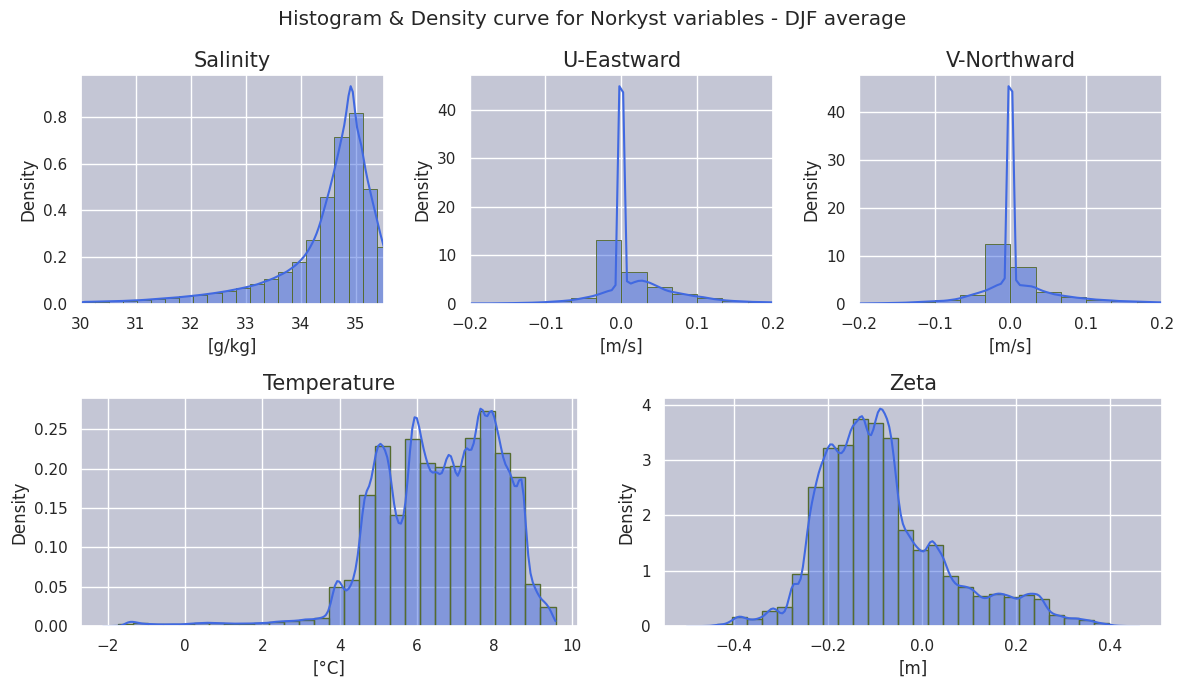

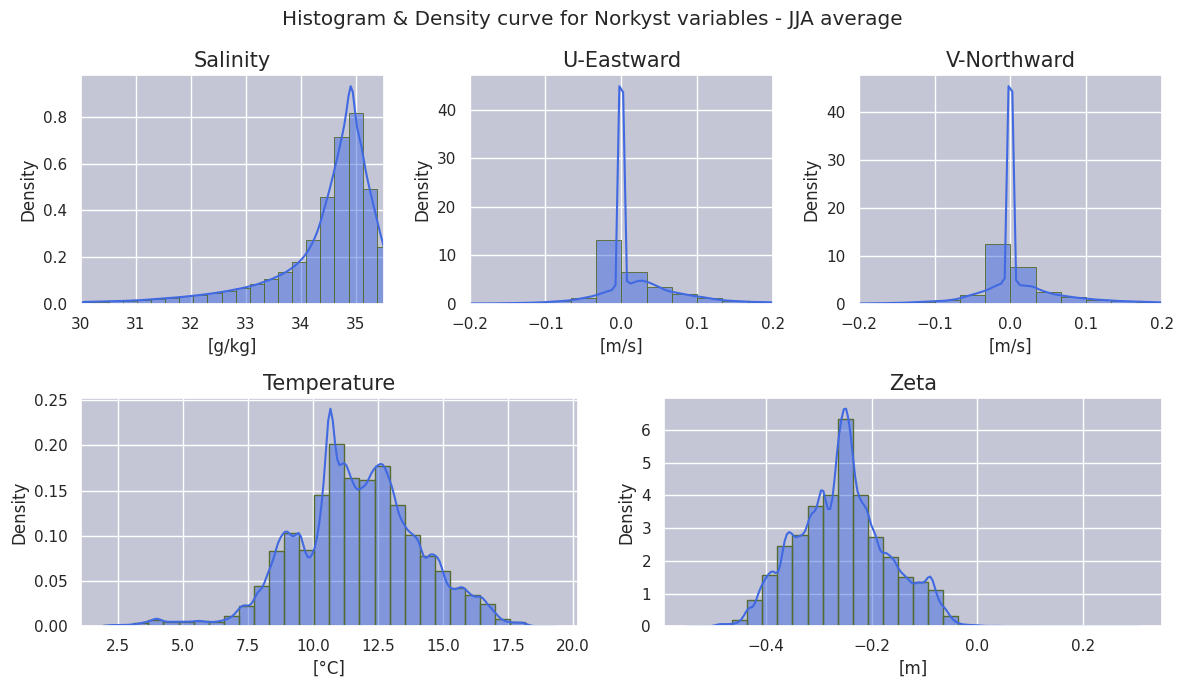

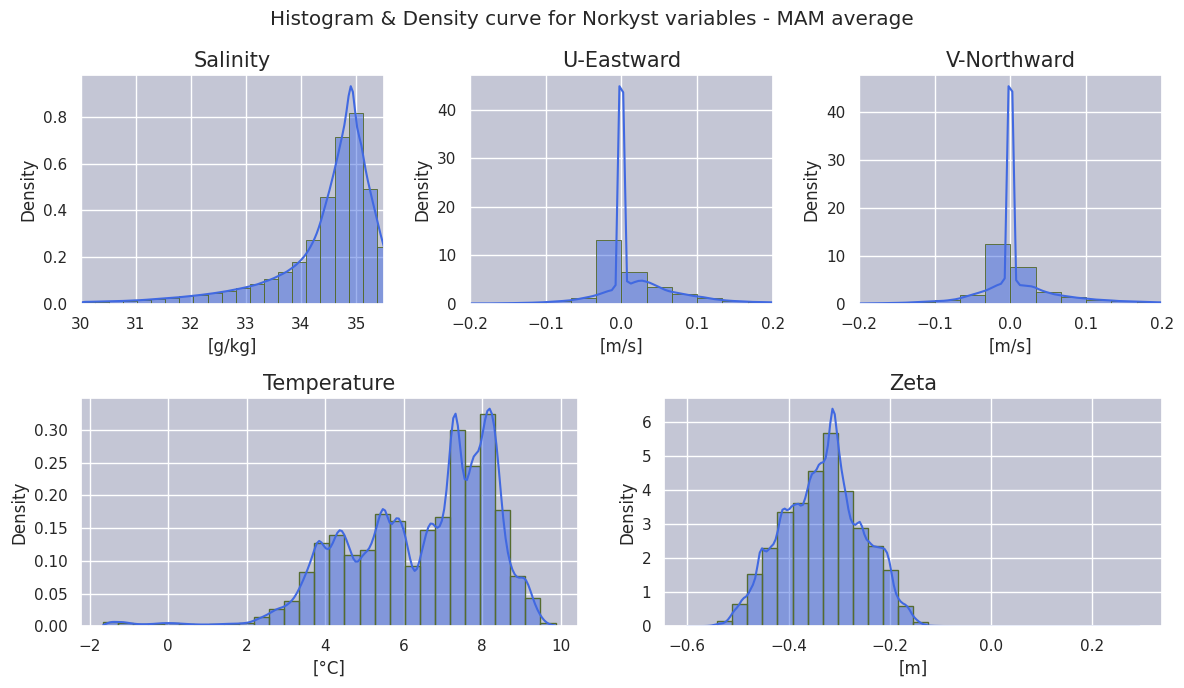

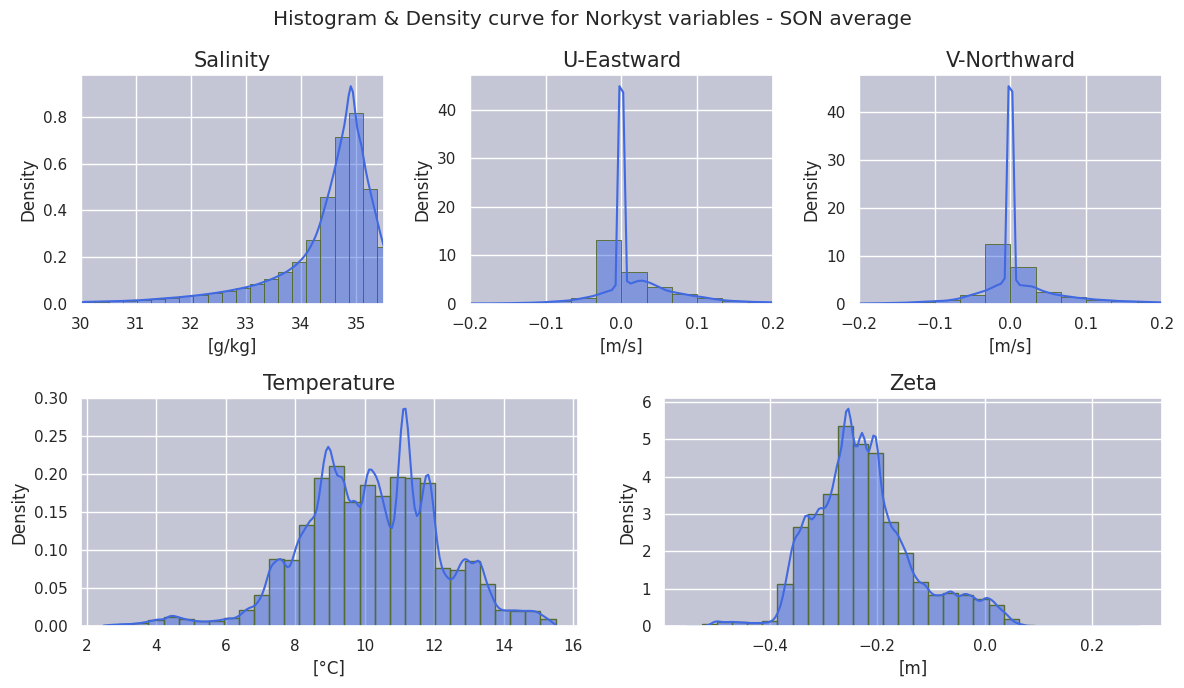

In [11]:
t = ['DJF', 'JJA', 'MAM', 'SON']
for i,n in enumerate(t):
    histograms_with_specified_layout(seasons_ds, f'{n}', type_to_check='season', time_to_check=i, save_path=f'/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_{n}.png')

In [22]:
def histograms_sidebyside(ds, type_of_avg, variable, x_label, type_to_check='time', time_to_check=[0, 1, 2, 3], save_path='figures/histogram.png'):
    """
    Plot histograms for each season side by side in one figure.
    """
    # Opprett data for de angitte tidsstegene
    data = {season: ds[variable].isel({type_to_check: time}).values.ravel() 
            for season, time in zip(['DJF', 'JJA', 'MAM', 'SON'], time_to_check)}

    # Filtrer data
    filtered_data = {}
    for season, time in zip(['DJF', 'JJA', 'MAM', 'SON'], time_to_check):
        season_data = ds[variable].isel({type_to_check: time}).values.ravel()
        
        # Filtrer basert på variabel
        if variable == 'salinity':
            season_data = ds['salinity'].isel({type_to_check: time}).where(ds['salinity'] > 30).values.ravel()
        elif variable in ['u_eastward', 'v_northward']:
            mask = (ds[variable] >= -0.5) & (ds[variable] <= 0.5)
            season_data = ds[variable].isel({type_to_check: time}).where(mask).values.ravel()
        
        # Fjern NaN-verdier
        filtered_data[season] = season_data[~np.isnan(season_data)]

    # Opprett subplot-layout
    fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(12, 7))
    axes = axes.flatten()  # Gjør det lett å iterere gjennom aksene
    titles = ['DJF', 'JJA', 'MAM', 'SON']

    # Plot data for hver sesong
    for i, (season, values) in enumerate(filtered_data.items()):
        sea.histplot(
            values,
            bins=50,
            kde=True,
            ax=axes[i],
            stat='density',
            color='royalblue',
            edgecolor='darkolivegreen'
        )
        axes[i].set_title(titles[i], fontsize=15)
        axes[i].set_facecolor("#C4C6D5")
        axes[i].set_xlabel(f'{x_label}', fontsize = 12)
        axes[i].set_ylabel('Probability Density', fontsize = 12)
        
        if variable == 'salinity':
            axes[i].set_xlim(30, 35.5)
            axes[i].set_ylim(0, 2)
        if variable == 'u_eastward' or variable == 'v_northward':
            axes[i].set_xlim(-0.2, 0.2)
            axes[i].set_yscale('log')
            axes[i].set_ylim(1e-1, 1e2)
        if variable == 'temperature': 
            axes[i].set_ylim(0, 0.3)
            axes[i].set_xlim(-2, 20)
        if variable == 'zeta' :
            axes[i].set_ylim(0, 6)
            axes[i].set_xlim(0, -0.7)


    # Fjern overflødige subplot (hvis noen)
    for j in range(len(filtered_data), len(axes)):
        fig.delaxes(axes[j])

    # Hovedtittel og lagring
    plt.suptitle(f'Histogram & Density curve for Havbris variables - {type_of_avg} average', fontsize = 16)
    plt.tight_layout()
    fig.savefig(save_path)

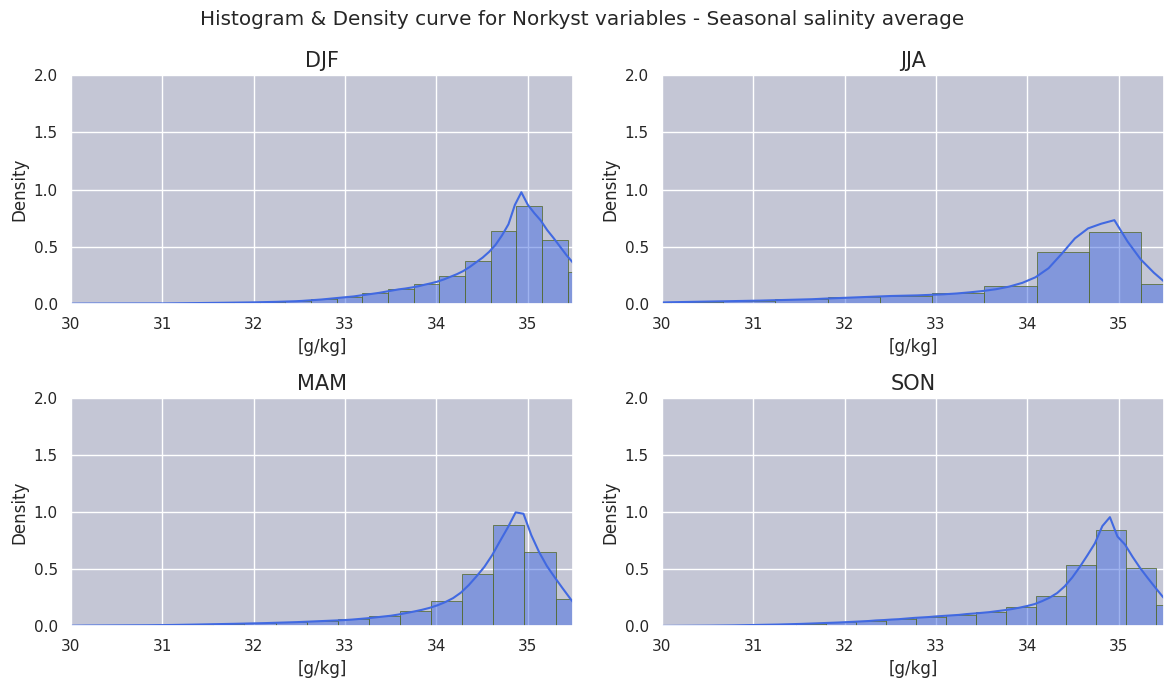

In [13]:
t = ['DJF', 'JJA', 'MAM', 'SON']
time_indices = [0, 1, 2, 3]

histograms_sidebyside(
    seasons_ds,
    type_of_avg='Seasonal salinity',
    variable='salinity',
    x_label='[g/kg]',
    type_to_check='season',
    time_to_check=time_indices,
    save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_salinity_HB.png'
)

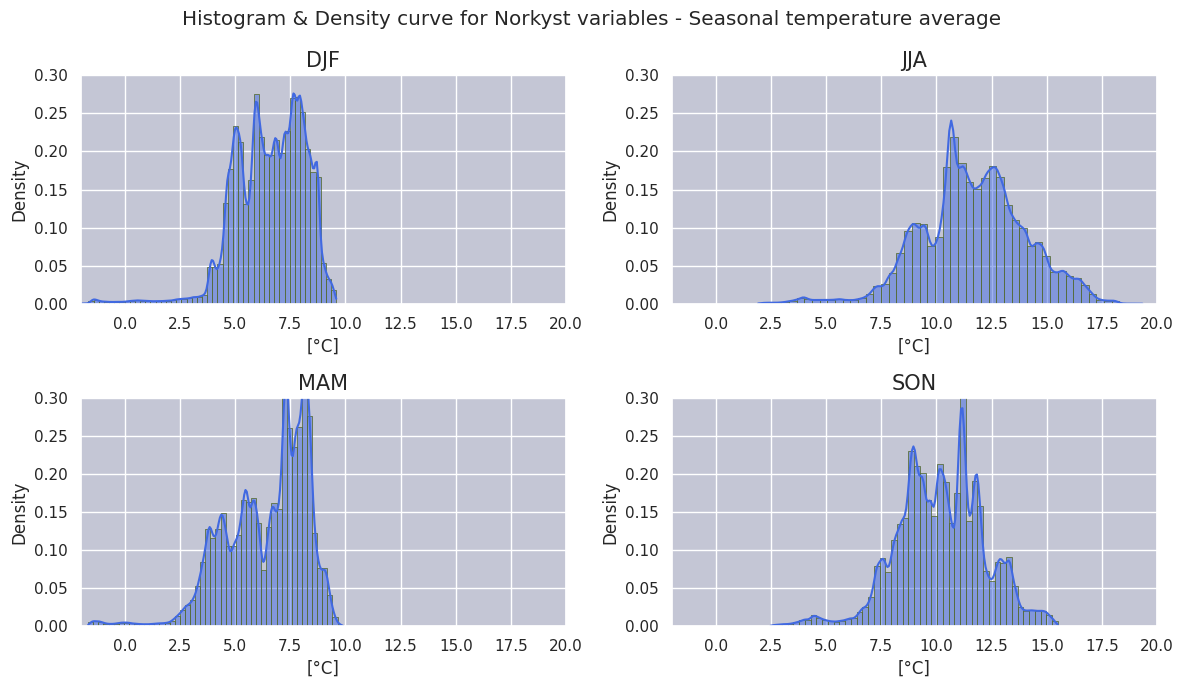

In [14]:
t = ['DJF', 'JJA', 'MAM', 'SON']
time_indices = [0, 1, 2, 3]

histograms_sidebyside(
    seasons_ds,
    type_of_avg='Seasonal temperature',
    variable='temperature',
    x_label='[°C]',
    type_to_check='season',
    time_to_check=time_indices,
    save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_temp_HB.png'
)

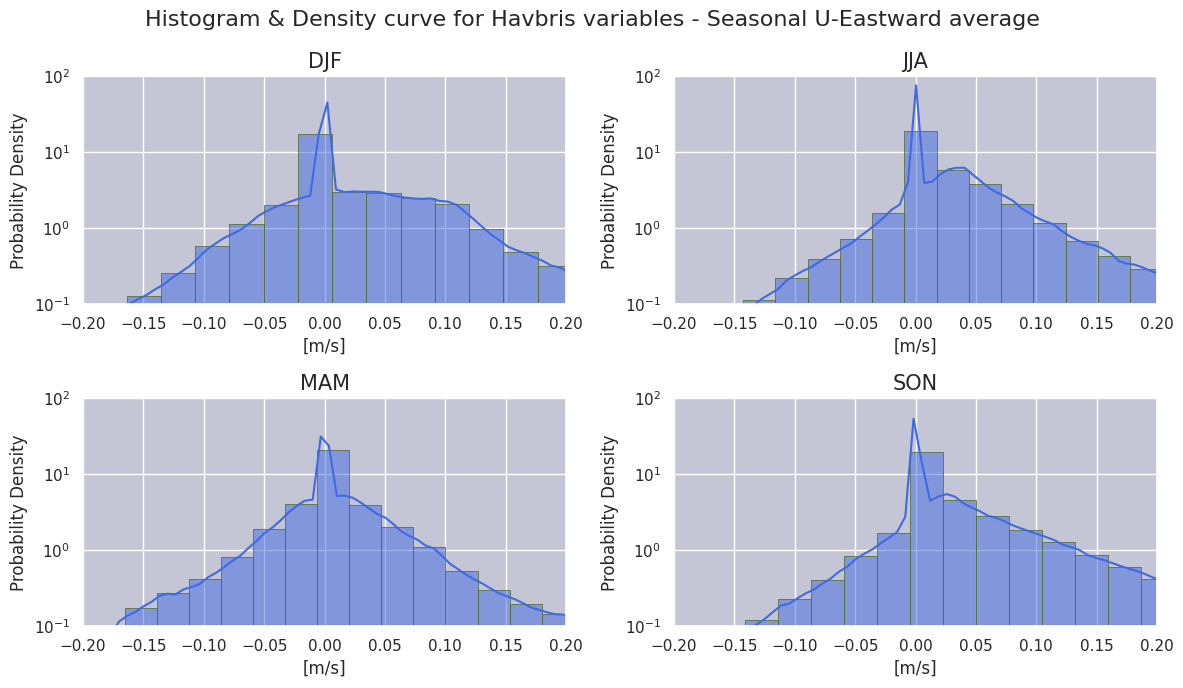

In [23]:
t = ['DJF', 'JJA', 'MAM', 'SON']
time_indices = [0, 1, 2, 3]

histograms_sidebyside(
    seasons_ds,
    type_of_avg='Seasonal U-Eastward',
    variable='u_eastward',
    x_label='[m/s]',
    type_to_check='season',
    time_to_check=time_indices,
    save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_u_HB.png')

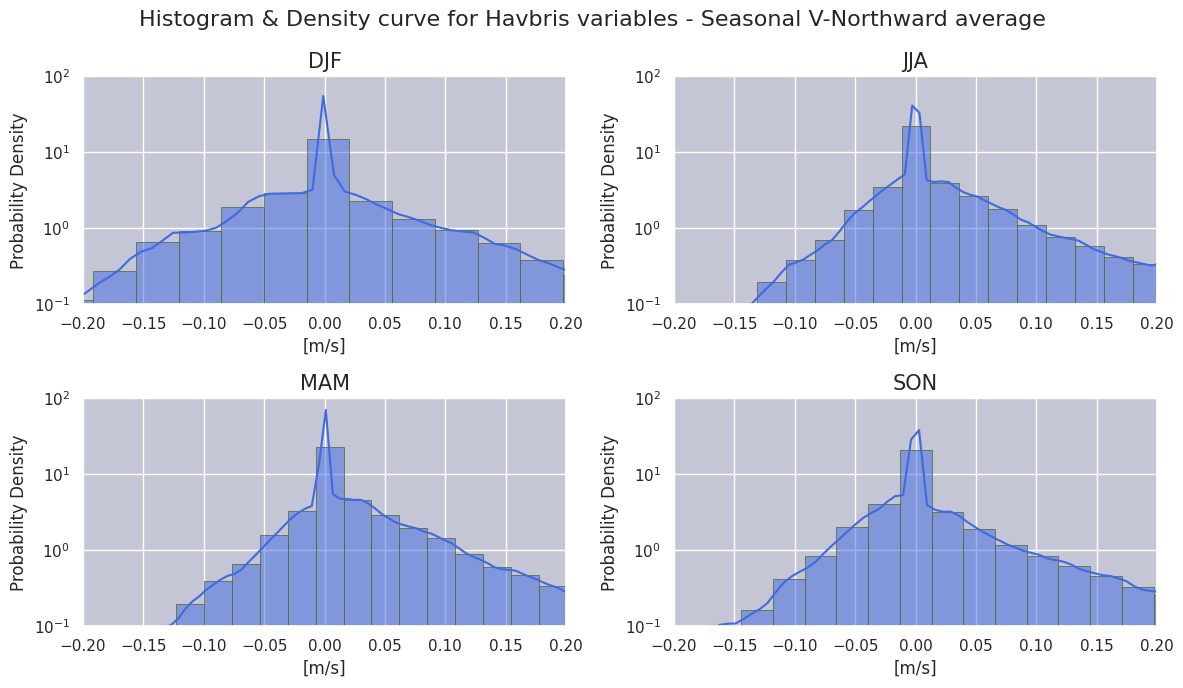

In [24]:
t = ['DJF', 'JJA', 'MAM', 'SON']
time_indices = [0, 1, 2, 3]

histograms_sidebyside(
    seasons_ds,
    type_of_avg='Seasonal V-Northward',
    variable='v_northward',
    x_label='[m/s]',
    type_to_check='season',
    time_to_check=time_indices,
    save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_v_HB.png'
)

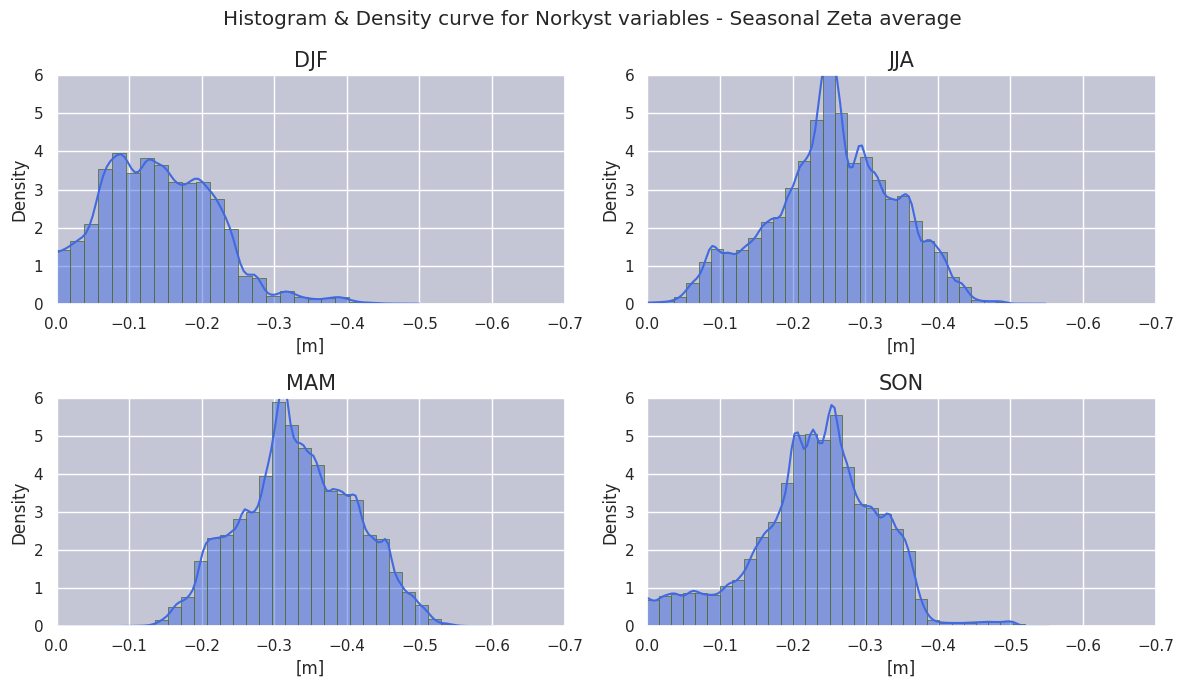

In [17]:
t = ['DJF', 'JJA', 'MAM', 'SON']
time_indices = [0, 1, 2, 3]

histograms_sidebyside(
    seasons_ds,
    type_of_avg='Seasonal Zeta',
    variable='zeta',
    x_label='[m]',
    type_to_check='season',
    time_to_check=time_indices,
    save_path='/lustre/storeB/project/fou/hi/foccus/malene/ocean-ai/plot/master/statistics/figures/season_z_HB.png'
)

# Checking the values of the tails


In [18]:
#select out the vars - starting off with salinity might be wise
salinity_y = year.salinity

In [19]:
salinity_vals = salinity_y.values
"""
less_than_thirty = 0 
for j in salinity_vals:
    if np.any(j < min_val):
        less_than_thirty += 1
"""
min_val = 30 
#mask
valid_salinity = salinity_vals[~np.isnan(salinity_vals)]
less_than_thirty = np.sum(  valid_salinity < min_val)
total_vals =       valid_salinity.size 
print(f'Number of outliers beneath a value of 30 is: {less_than_thirty}')
outliers = (less_than_thirty / total_vals) * 100 
print(f'The outliers make up: {outliers:.2f} %')

Number of outliers beneath a value of 30 is: 80355
The outliers make up: 2.20 %


In [20]:
#Function for finding outliers based on a given reference value
def outliers_reference(ds):
    """ 
    Arg[1] : ds - please provide an averaged dataset
    """
    #Select vals
    salinity    = ds['salinity'].values 
    temperature = ds['temperature'].values
    u           = ds['u_eastward'].values 
    v           = ds['v_northward'].values 
    zeta        = ds['zeta'].values 
    
    #Filter out nans (land-values)
    valid_salinity    = salinity[~np.isnan(salinity)]
    valid_temperature = temperature[~np.isnan(temperature)]
    valid_u           = u[~np.isnan(u)]
    valid_v           = v[~np.isnan(v)]
    valid_zeta        = zeta[~np.isnan(zeta)] 
    
    # Defining reference values
    salt_min = 0 #Salt cannot physically be less then zero
    salt_max = 30
    temp_min = -2
    temp_max = 20
    u_v_min = -0.2
    u_v_max = 0.2
    zeta_min = -0.70
    zeta_max = 0.0 

    #Calculating
    salinity_outliers    , size_orig_s  =  np.sum(valid_salinity < salt_max)     , valid_salinity.size 
    temperature_outliers , size_orig_t  =  np.sum((valid_temperature < temp_min) | (valid_temperature > temp_max)) , valid_temperature.size
    u_outliers           , size_orig_u  =  np.sum((valid_u < u_v_min ) | (valid_u > u_v_max))              , valid_u.size
    v_outliers           , size_orig_v  =  np.sum((valid_v < u_v_min ) | (valid_v > u_v_max))              , valid_v.size
    zeta_outliers        , size_orig_z  =  np.sum((valid_zeta < zeta_min) | (valid_zeta > zeta_max))         , valid_zeta.size

    outlier_percentage_s = (salinity_outliers / size_orig_s) * 100 
    outlier_percentage_t = (temperature_outliers / size_orig_t) * 100 
    outlier_percentage_u = ( u_outliers / size_orig_u ) * 100 
    outlier_percentage_v = ( v_outliers / size_orig_v ) * 100 
    outlier_percentage_z = ( zeta_outliers / size_orig_z  ) * 100  

    for o, n in zip([outlier_percentage_s, outlier_percentage_t, outlier_percentage_u, outlier_percentage_v, outlier_percentage_z], ['salinity', 'temperature', 'u_northward', 'v_northward', 'zeta']):
        print(f'The percentage of outliers in {n} is: {o:.2f}%') 


In [21]:
outliers_reference(year)

The percentage of outliers in salinity is: 2.20%
The percentage of outliers in temperature is: 0.00%
The percentage of outliers in u_northward is: 9.12%
The percentage of outliers in v_northward is: 9.88%
The percentage of outliers in zeta is: 39.05%


In [26]:
import cartopy
import cmocean #using haline cmocean color 
import cartopy.crs as ccrs #cartopy north stereo
import cartopy.feature as cfeature

<xarray.DataArray 'salinity' (Y: 1148, X: 2747)> Size: 13MB
array([[nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       ...,
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan],
       [nan, nan, nan, ..., nan, nan, nan]],
      shape=(1148, 2747), dtype=float32)
Coordinates:
  * Y        (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.16e+05 9.168e+05 9.176e+05
  * X        (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
    time     datetime64[ns] 8B 2024-12-31


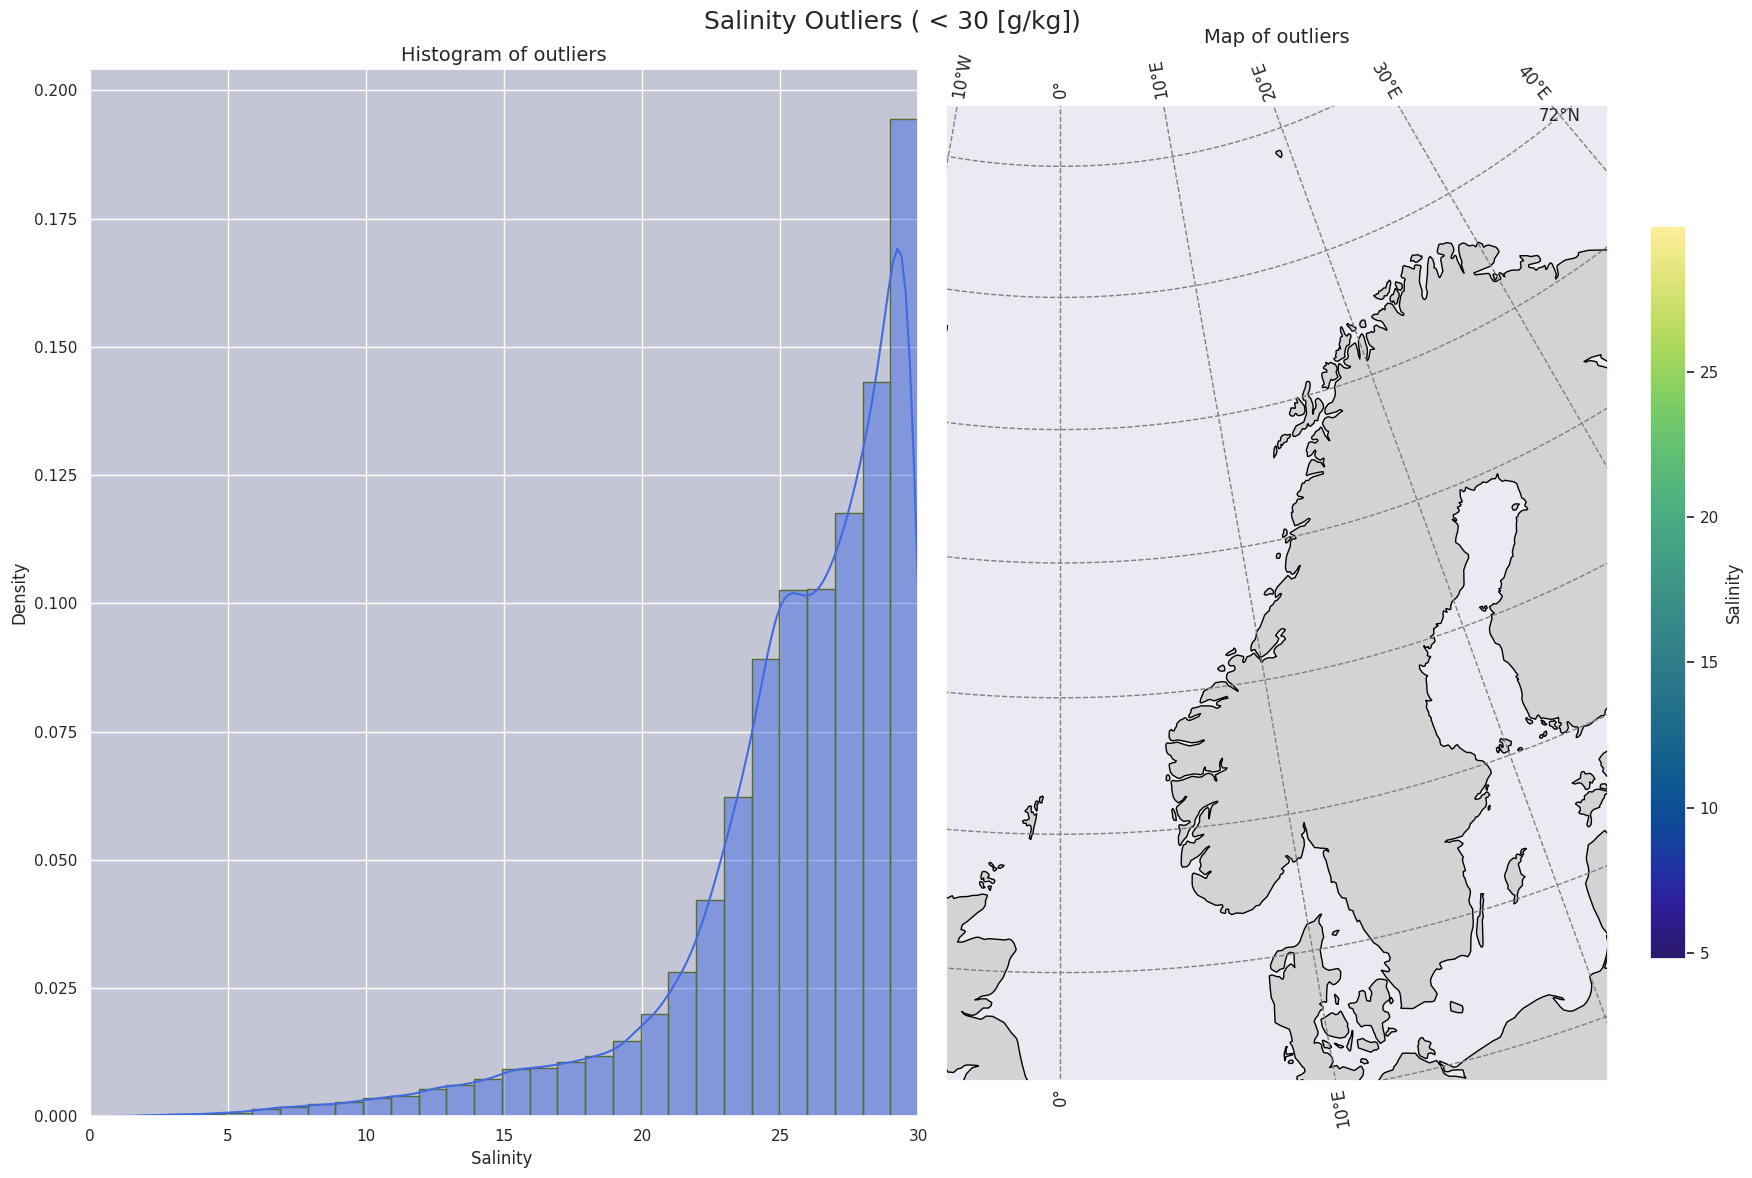

In [27]:

fig = plt.figure(figsize=(18, 12))

# Opprett to subplotter: én vanlig akse for histogram og én kartprojeksjon
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1])  
ax_hist = fig.add_subplot(gs[0])  # Histogram-akse (vanlig 2D-akse)
ax_map = fig.add_subplot(gs[1], projection=ccrs.NorthPolarStereo())  # Kartprojeksjon

# Salinitetsdata
saltttt = year.salinity

# Maskerer verdier over 30 (outliers) og flatt ut arrayen
cleaned_salinity = saltttt.where(saltttt < 30)  # Mask verdier >= 30
raveled_cleaned_salinity = cleaned_salinity.values.ravel()
raveled_cleaned_salinity = raveled_cleaned_salinity[~np.isnan(raveled_cleaned_salinity)]  # Fjern NaN

# Histogram
sea.histplot(raveled_cleaned_salinity, bins=30, kde=True, ax=ax_hist, stat='density',
             color='royalblue', edgecolor='darkolivegreen')
ax_hist.set_facecolor("#C4C6D5")
ax_hist.grid(True)
ax_hist.set_xlim(0, 30)  # Begrens x-aksen til 0–30
ax_hist.set_title("Histogram of outliers", fontsize=14,)
ax_hist.set_xlabel("Salinity ", fontsize=12)
ax_hist.set_ylabel("Density", fontsize=12)

# Kart: Plott salinitet
lon = cleaned_salinity.X
lat = cleaned_salinity.Y
salinity_data = cleaned_salinity[0, :, :]
print(salinity_data)

pcm = ax_map.pcolormesh(lon, lat, salinity_data, cmap=cmocean.cm.haline,
                        transform=ccrs.PlateCarree(), shading='auto')

# Legg til land, grid og koordinater
ax_map.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='lightgray')
ax_map.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), color='gray', linestyle='--')
ax_map.set_title('Map of outliers', fontsize=14)
norway = [-4.2, 20.5, 54.6, 75.5]
ax_map.set_extent(norway, crs=ccrs.PlateCarree())
# Fargebar: Match høyden til kartet
cbar = fig.colorbar(pcm, ax=ax_map, orientation='vertical', shrink=0.7, pad=0.05)
cbar.set_label("Salinity", fontsize=12)
plt.suptitle(f'Salinity Outliers ( < 30 [g/kg])', fontsize = 18)

# Juster layout
plt.tight_layout()
plt.show()

In [24]:
year

<xarray.Dataset> Size: 126MB
Dimensions:      (Y: 1148, X: 2747, time: 2)
Coordinates:
  * Y            (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.168e+05 9.176e+05
  * X            (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
  * time         (time) datetime64[ns] 16B 2024-12-31 2025-12-31
Data variables:
    salinity     (time, Y, X) float32 25MB nan nan nan nan ... 34.4 34.38 34.39
    temperature  (time, Y, X) float32 25MB nan nan nan ... 0.7734 0.7119 0.6896
    v_northward  (time, Y, X) float32 25MB 9.878e-06 6.854e-05 ... 0.01544
    u_eastward   (time, Y, X) float32 25MB 0.0001618 0.0002536 ... -0.06535
    zeta         (time, Y, X) float32 25MB nan nan nan ... -0.2578 -0.2578

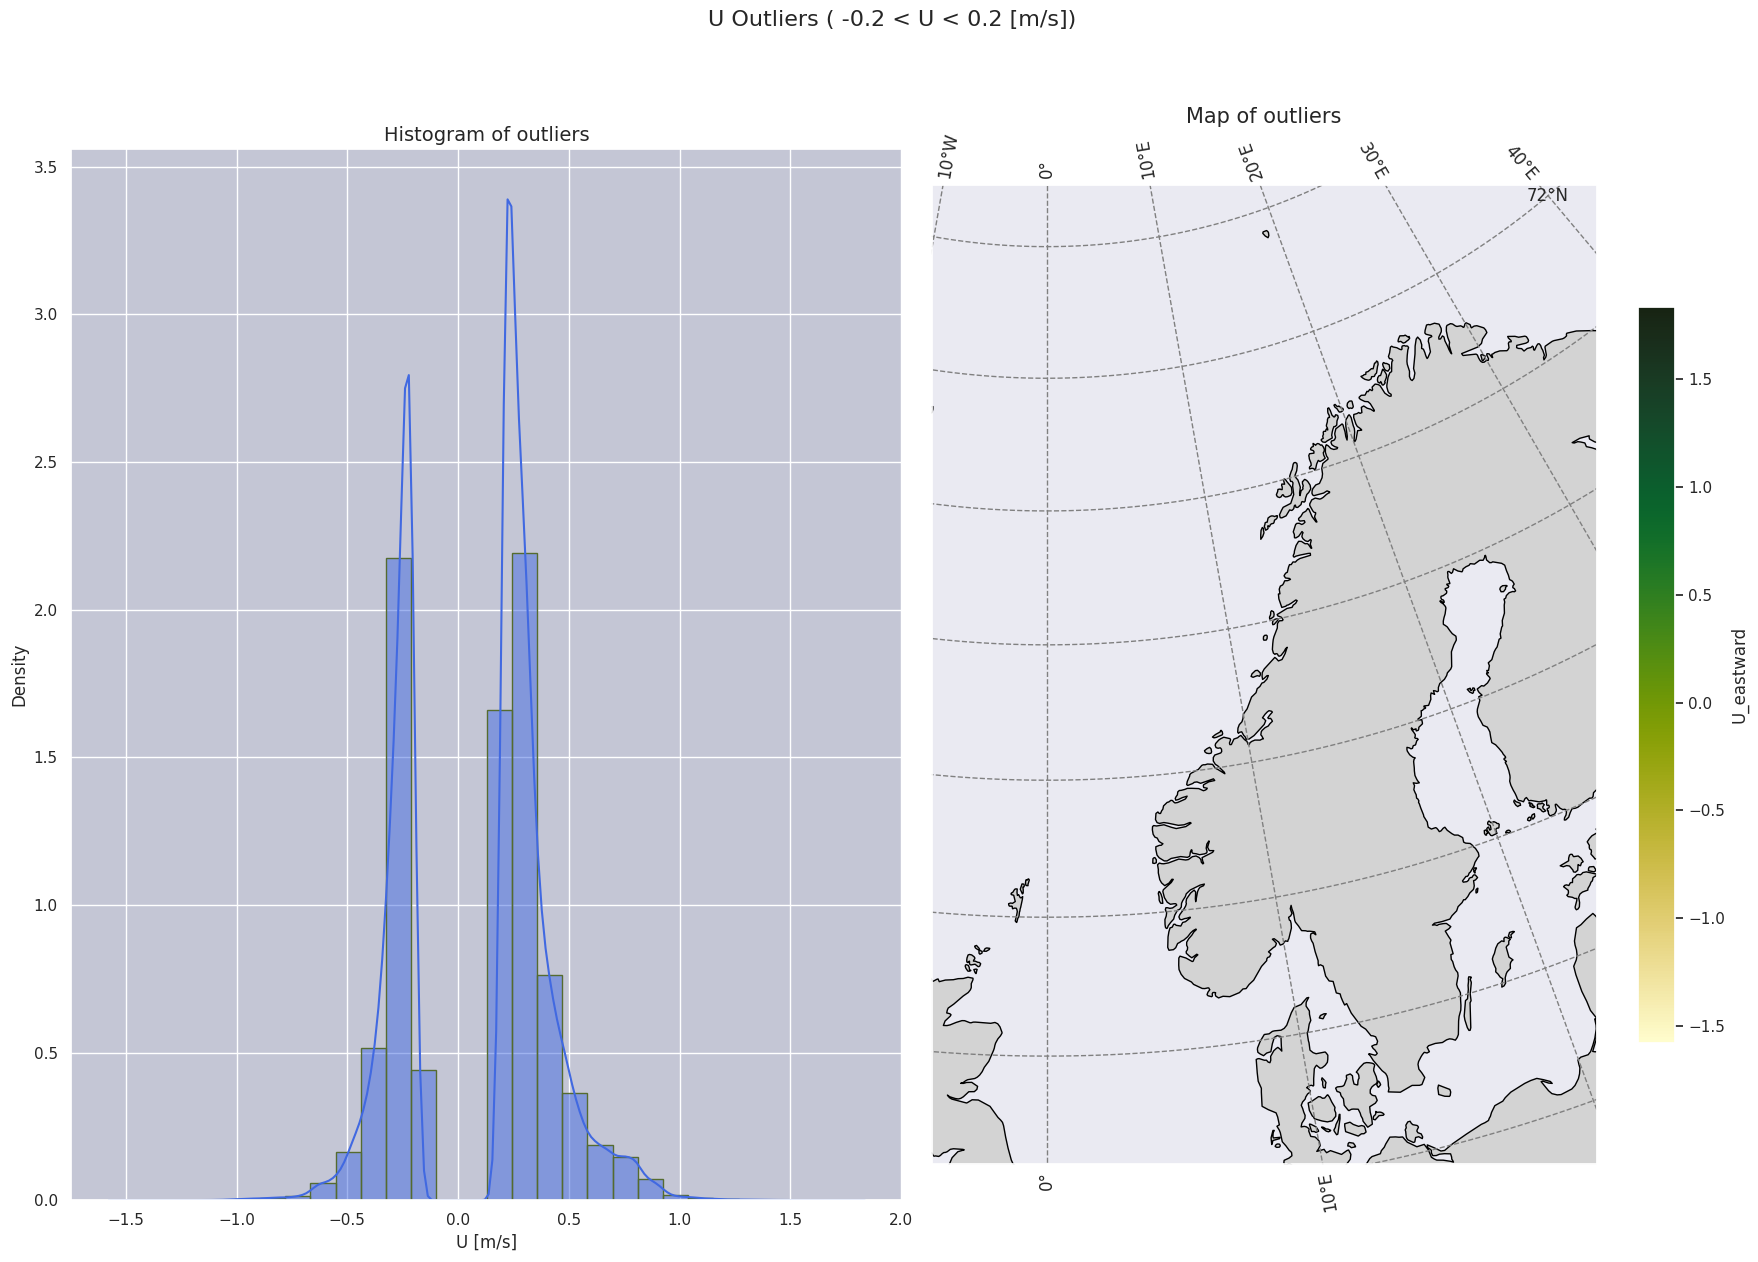

In [43]:
fig = plt.figure(figsize=(18, 12))

# Opprett to subplotter: én vanlig akse for histogram og én kartprojeksjon
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1])  # Gi kartet mer plass
ax_hist = fig.add_subplot(gs[0])  # Histogram-akse (vanlig 2D-akse)
ax_map = fig.add_subplot(gs[1], projection=ccrs.NorthPolarStereo())  # Kartprojeksjon

u = year.u_eastward
u_v_min = -0.2
u_v_max = 0.2
# Mask verdier over 30 (outliers) og flatt ut arrayen
cleaned_u = u.where((u < u_v_min ) | (u > u_v_max))  # Mask verdier >= 30
raveled_cleaned_u = cleaned_u.values.ravel()
raveled_cleaned_u = raveled_cleaned_u[~np.isnan(raveled_cleaned_u)]  # Fjern NaN

# Histogram
sea.histplot(raveled_cleaned_u, bins=30, kde=True, ax=ax_hist, stat='density',
             color='royalblue', edgecolor='darkolivegreen')
ax_hist.set_facecolor("#C4C6D5")
ax_hist.grid(True)
# Juster histogramakser
#ax_hist.set_xlim(0, 30)  # Begrens x-aksen til 0–30
ax_hist.set_title("Histogram of outliers", fontsize=14,)
ax_hist.set_xlabel("U [m/s]", fontsize=12)
ax_hist.set_ylabel("Density", fontsize=12)

# Kart: Plott salinitet
lon = u.X
lat = u.Y

pcm = ax_map.pcolormesh(lon,lat, cleaned_u[1,:,:], cmap=cmocean.cm.speed, transform=ccrs.PlateCarree())#, shading='auto')
# Legg til land, grid og koordinater
ax_map.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='lightgray')
ax_map.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), color='gray', linestyle='--')
ax_map.set_title('Map of outliers', fontsize=15)
norway = [-4.2, 20.5, 54.6, 75.5]
ax_map.set_extent(norway, crs=ccrs.PlateCarree())

# Fargebar: Match høyden til kartet
cbar = fig.colorbar(pcm, ax=ax_map, orientation='vertical', shrink=0.7, pad=0.05)
cbar.set_label("U_eastward", fontsize=12)
plt.suptitle(f'U Outliers ( -0.2 < U < 0.2 [m/s])', fontsize = 16, y = 1.05)

# Juster layout
plt.tight_layout()
plt.show()

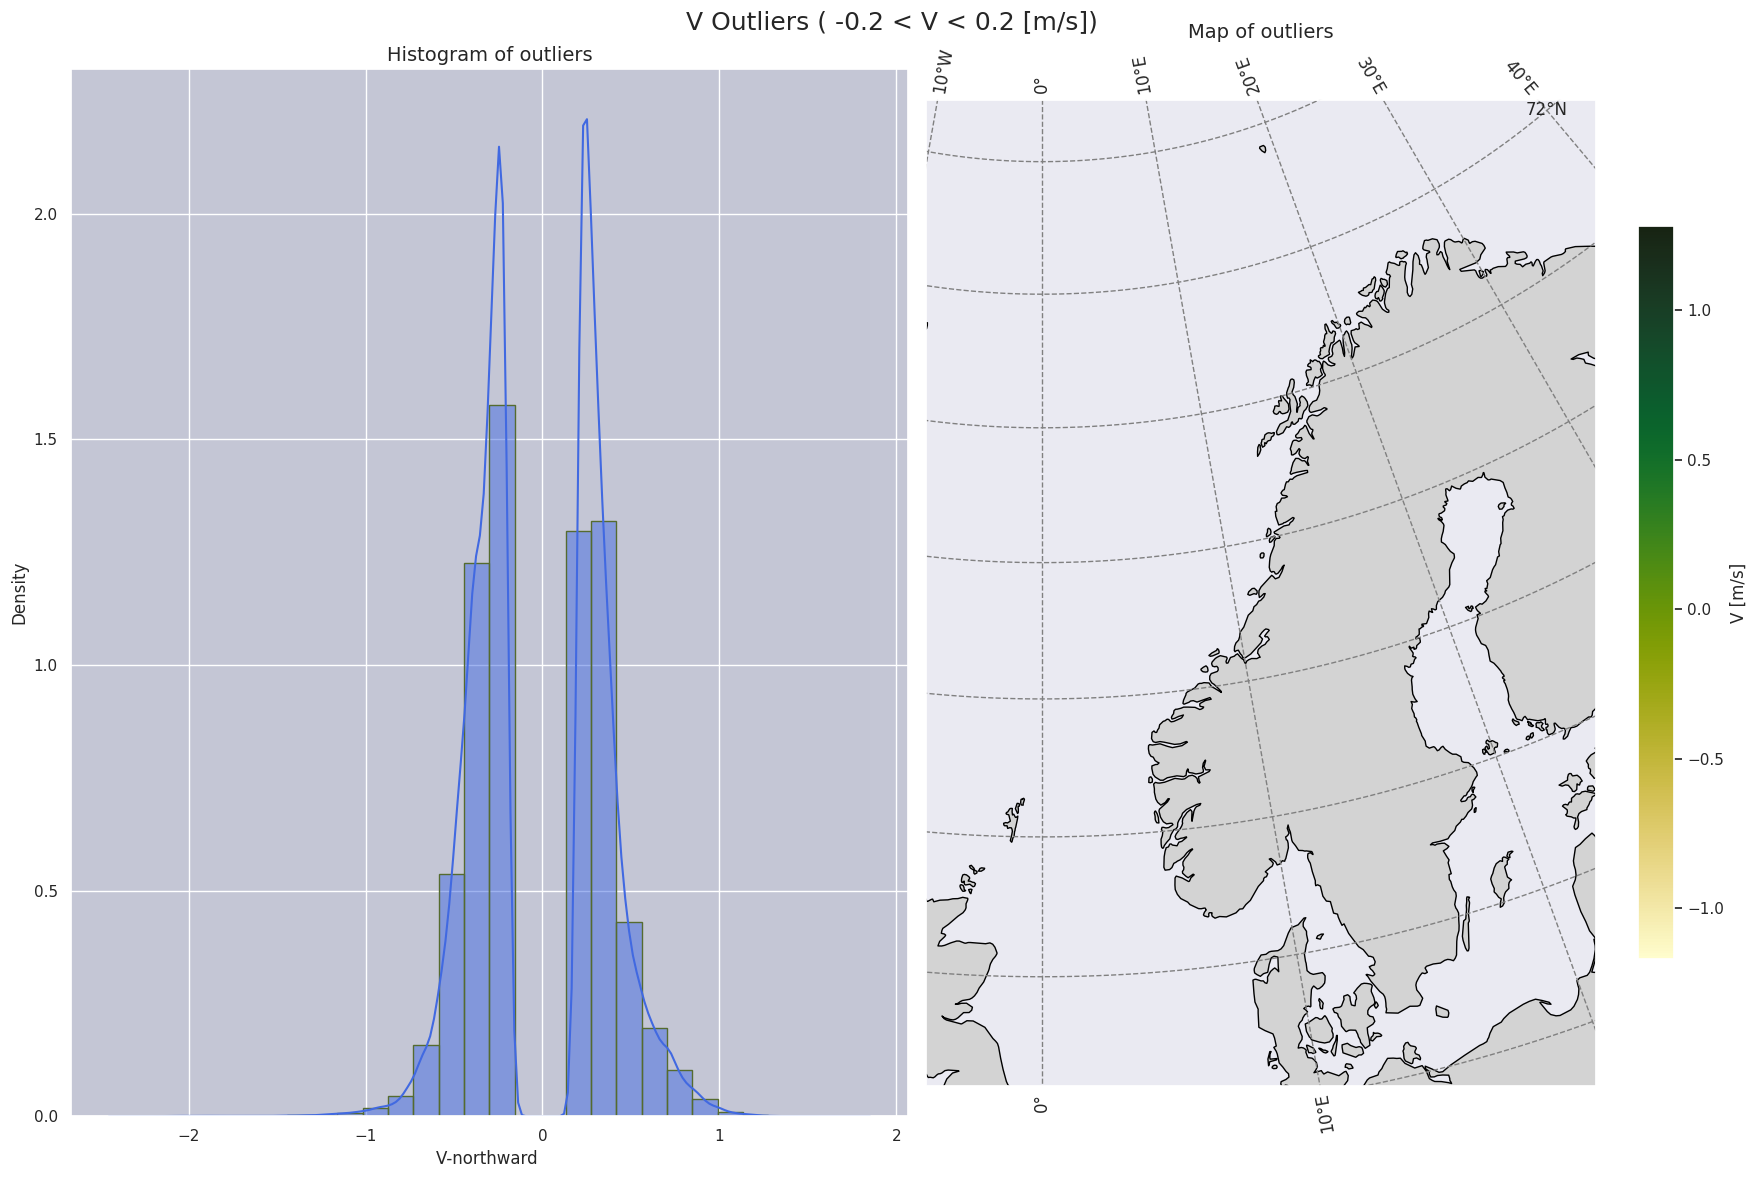

In [ ]:
fig = plt.figure(figsize=(18, 12))

# Opprett to subplotter: én vanlig akse for histogram og én kartprojeksjon
gs = fig.add_gridspec(1, 2, width_ratios=[1, 1])  # Gi kartet mer plass
ax_hist = fig.add_subplot(gs[0])  # Histogram-akse (vanlig 2D-akse)
ax_map = fig.add_subplot(gs[1], projection=ccrs.NorthPolarStereo())  # Kartprojeksjon

# Salinitetsdata
v = year.v_northward

# Mask verdier over 30 (outliers) og flatt ut arrayen
cleaned_v = v.where((v < u_v_min ) | (v > u_v_max))  # Mask verdier >= 30
raveled_cleaned_v = cleaned_v.values.ravel()
raveled_cleaned_v = raveled_cleaned_v[~np.isnan(raveled_cleaned_v)]  # Fjern NaN

# Histogram
sea.histplot(raveled_cleaned_v, bins=30, kde=True, ax=ax_hist, stat='density',
             color='royalblue', edgecolor='darkolivegreen')
ax_hist.set_facecolor("#C4C6D5")
ax_hist.grid(True)
# Juster histogramakser
#ax_hist.set_xlim(0, 30)  # Begrens x-aksen til 0–30
ax_hist.set_title("Histogram of outliers", fontsize=14,)
ax_hist.set_xlabel("V-northward ", fontsize=12)
ax_hist.set_ylabel("Density", fontsize=12)

# Kart: Plott salinitet
lon = cleaned_v.X
lat = cleaned_v.Y

pcm = ax_map.pcolormesh(lon, lat, v_data, cmap=cmocean.cm.speed,
                        transform=ccrs.PlateCarree(), shading='auto')

# Legg til land, grid og koordinater
ax_map.add_feature(cfeature.LAND, zorder=1, edgecolor='black', facecolor='lightgray')
ax_map.gridlines(draw_labels=True, crs=ccrs.PlateCarree(), color='gray', linestyle='--')
ax_map.set_title('Map of outliers', fontsize=14)

norway = [-4.2, 20.5, 54.6, 75.5]
ax_map.set_extent(norway, crs=ccrs.PlateCarree())

# Fargebar: Match høyden til kartet
cbar = fig.colorbar(pcm, ax=ax_map, orientation='vertical', shrink=0.7, pad=0.05)
cbar.set_label("V [m/s]", fontsize=12)
plt.suptitle(f'V Outliers ( -0.2 < V < 0.2 [m/s])', fontsize = 18)

# Juster layout
plt.tight_layout()
plt.show()

In [30]:

u = year.u_eastward
u_v_min = -0.2
u_v_max = 0.2
# Mask verdier over 30 (outliers) og flatt ut arrayen
cleaned_u = u.where((u < u_v_min ) | (u > u_v_max))  # Mask verdier >= 30
raveled_cleaned_u = cleaned_u.values.ravel()
raveled_cleaned_u = raveled_cleaned_u[~np.isnan(raveled_cleaned_u)]  # Fjern NaN

# Kart: Plott salinitet
lon = cleaned_u.X
lat = cleaned_u.Y
u_data = cleaned_u[0, :, :]  # Antar første tidssteg hvis det er 3D-data

In [34]:
cleaned_u

<xarray.DataArray 'u_eastward' (time: 2, Y: 1148, X: 2747)> Size: 25MB
array([[[        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        ...,
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan]],

       [[        nan,         nan,         nan, ..., -0.22281425,
         -0.23724216, -0.24607302],
        [        nan,         nan,         nan, ..., -0.20632997,
         -0.20545106, -0.20486233],
        [        nan,         nan,         nan, ..., -0.22781424,
         -0.23011279, -0.2159834 ],
        ...,
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan],
        [        nan,         nan,         nan, ...,         nan,
                 nan,         nan]]], shape=(2, 1148, 2747), dtype=float32)
Coordinates:
  * Y        (Y) float64 9kB 0.0 800.0 1.6e+03 ... 9.16e+05 9.168e+05 9.176e+05
  * X        (X) float64 22kB 0.0 800.0 1.6e+03 ... 2.196e+06 2.197e+06
  * time     (time) datetime64[ns] 16B 2024-12-31 2025-12-31

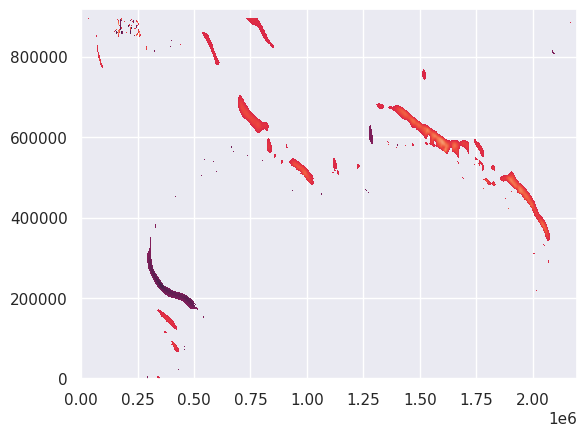

In [48]:
plt.pcolormesh(lon, lat, cleaned_u[0,:,:])